In [73]:
import pandas as pd
import numpy as np
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split,cross_val_score,RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer
)
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression,RidgeCV,LassoCV
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.base import clone
import joblib

In [2]:
base_path = Path().cwd().parent
data_path = base_path/"data"
model_path = base_path/"model"

# Step 1: Problem Framing & Theory Notes

## 1. Regression vs Classification

**Regression** predicts continuous numerical values, e.g., predicting house prices or crop yield in Maharashtra.

**Classification** predicts categories, e.g., predicting whether a bank customer will default on a loan.

## 2. Types of Regression

- **Simple Linear Regression:** Uses one feature to predict the target.
- **Multiple Linear Regression:** Uses two or more features.
- **Ridge (L2):** Shrinks coefficients to reduce overfitting.
- **Lasso (L1):** Can make coefficients zero and select important features.

## 3. Overfitting and Underfitting

- **Overfitting:** Model performs well on training data but poorly on unseen data.
- **Underfitting:** Model is too simple and performs poorly on both training and test data.
- **Regularisation:** L1 and L2 penalties help control model complexity and reduce overfitting.

## 4. Evaluation Metrics

- **RMSE:** Measures prediction error and penalises large errors more.
- **MAE:** Measures average absolute prediction error.
- **R²:** Measures how much variation in the target is explained by the model.

**RMSE is preferred over MAE** when large prediction errors should receive greater penalty.

## 5. Cross-Validation (K-Fold)

K-Fold Cross-Validation divides data into K parts. The model trains on K−1 folds and validates on the remaining fold, repeating until every fold has been used for validation.

It is preferred over a single split because it provides a more reliable estimate of model performance and shows how stable the results are across different splits.

# Step 2: Dataset Loading & Exploratory Data Analysis

## Load & Understand the Dataset

In [3]:
# Load train.csv using pandas. Print .shape, .info(), and .describe().
df = pd.read_csv(data_path/"train.csv")

display(df.head())

print("\nshape:",df.shape)

print("\ninfo:")
display(df.info())

print("\nDescribe:")
display(df.describe())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



shape: (1460, 81)

info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-nu

None


Describe:


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [4]:
# how many numarical and categorical columns
num_col = df.select_dtypes(include=["int64","float64"]).columns.tolist()

cat_col = df.select_dtypes(include=["object"]).columns.tolist()

print("\nNumerical Columns:")
print(num_col)

print("\nCategorical Columns:")
print(cat_col)

print("\nTotal Num:",len(num_col))
print("\nTotal cat:",len(cat_col))


Numerical Columns:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Categorical Columns:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'Firepla

In [5]:
# Missing values
isnull_df = df.isnull().sum()
isnull_pr = round(df.isnull().mean() *100,2)

isnull_df = pd.DataFrame({
    "Columns":isnull_df.index,
    "Missing Count":isnull_df.values,
    "Missing %":isnull_pr.values
})

display(isnull_df[isnull_df["Missing Count"]>0])

,Columns,Missing Count,Missing %
3,LotFrontage,259,17.74
6,Alley,1369,93.77
25,MasVnrType,872,59.73
26,MasVnrArea,8,0.55
30,BsmtQual,37,2.53
31,BsmtCond,37,2.53
32,BsmtExposure,38,2.60
33,BsmtFinType1,37,2.53
35,BsmtFinType2,38,2.60
42,Electrical,1,0.07


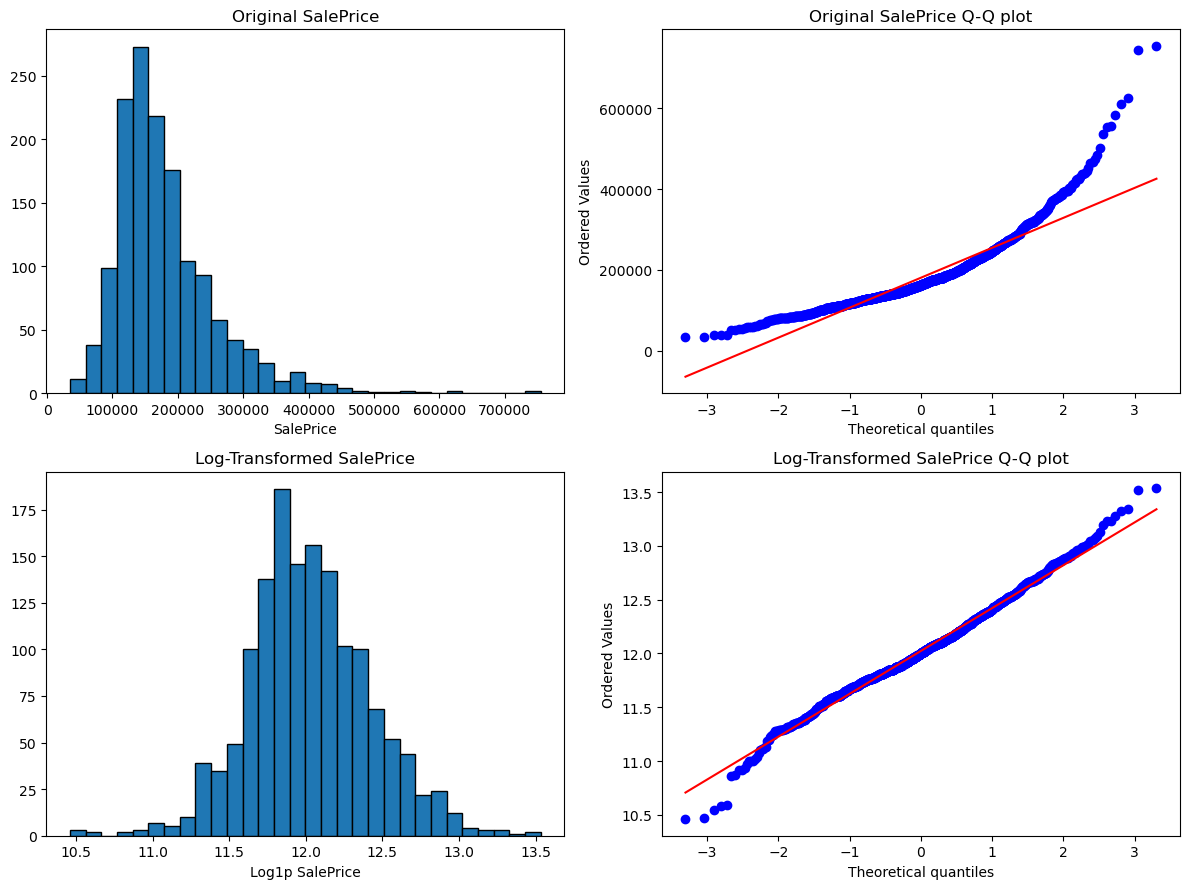

In [6]:
# Plot a histogram and Q-Q plot of the target variable SalePrice. 
# log1p transformation and re-plot.
y  = df["SalePrice"]

y_log = np.log1p(y)

fig,axes = plt.subplots(2,2,figsize=(12,9))

axes[0,0].hist(y,bins=30,edgecolor = "black")
axes[0,0].set_title("Original SalePrice")
axes[0,0].set_xlabel("SalePrice")

stats.probplot(y,dist = "norm",plot=axes[0,1])
axes[0,1].set_title("Original SalePrice Q-Q plot")

axes[1,0].hist(y_log,bins=30,edgecolor = "black")
axes[1,0].set_title("Log-Transformed SalePrice")
axes[1,0].set_xlabel("Log1p SalePrice")

stats.probplot(y_log,dist = "norm",plot=axes[1,1])
axes[1,1].set_title("Log-Transformed SalePrice Q-Q plot")

plt.tight_layout()
plt.show()

## Univariate Analysis

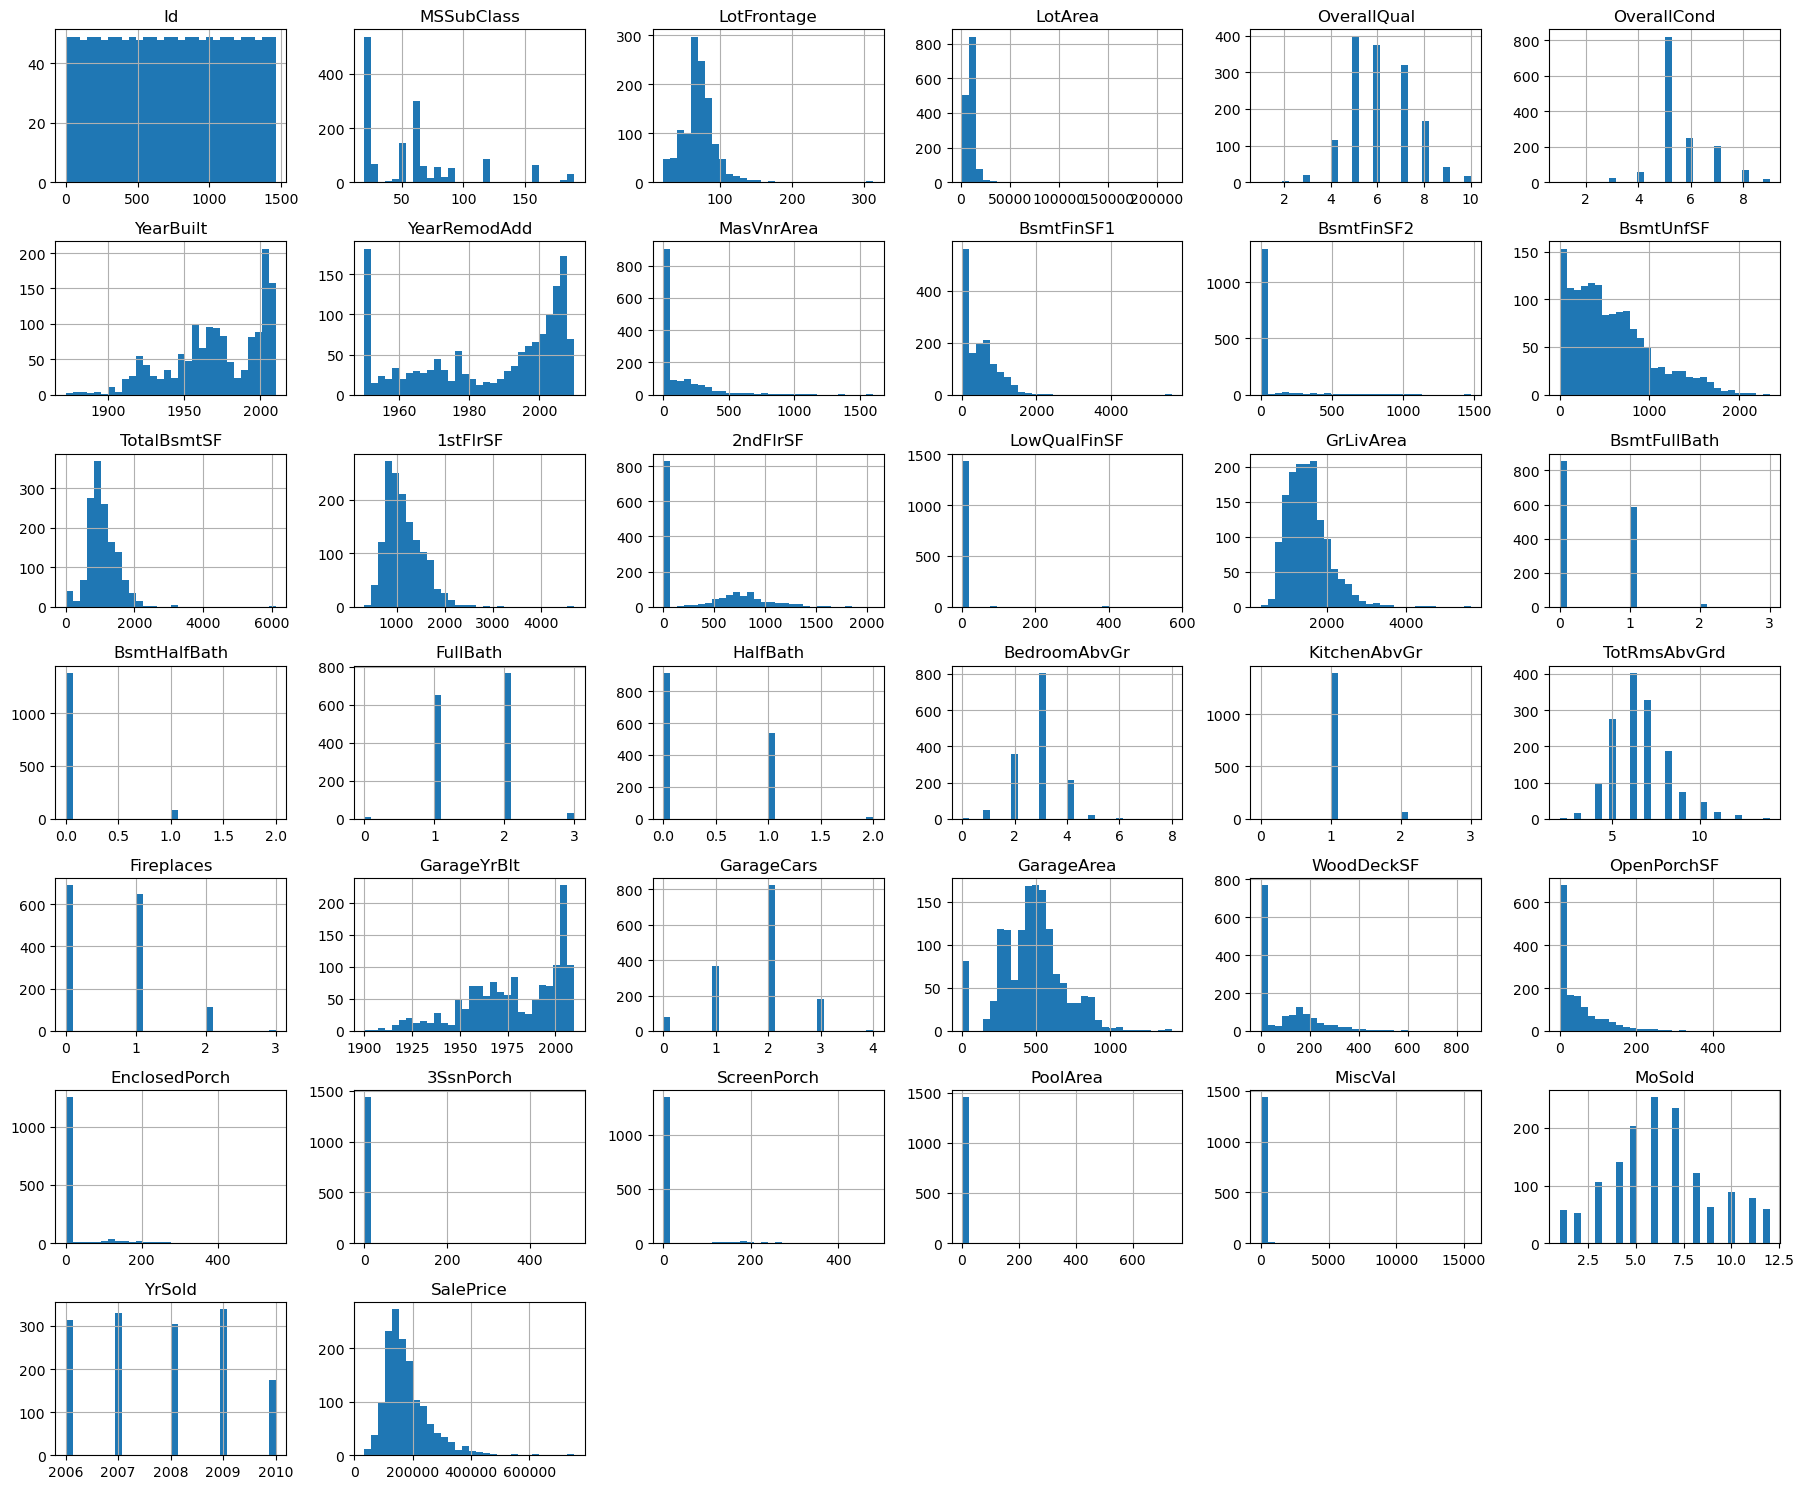

MiscVal         24.476794
PoolArea        14.828374
LotArea         12.207688
3SsnPorch       10.304342
LowQualFinSF     9.011341
dtype: float64


In [7]:
df[num_col].hist(figsize=(18, 15), bins=30)
plt.tight_layout()
plt.show()

skew = df[num_col].skew()
print(skew.abs().sort_values(ascending=False).head(5))

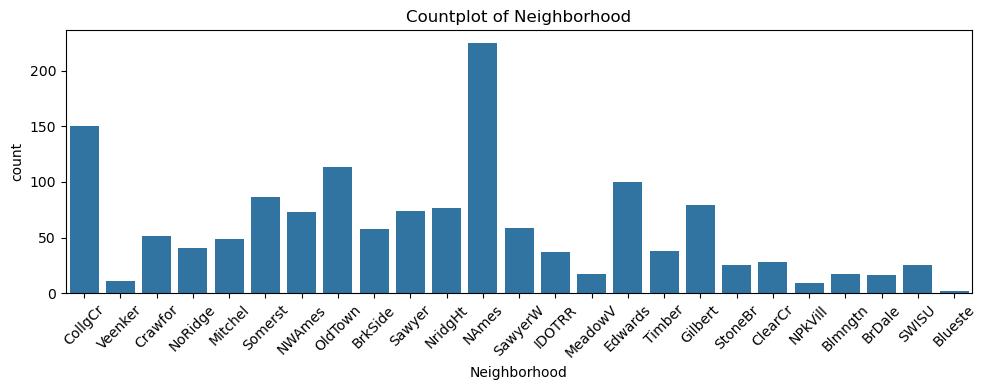

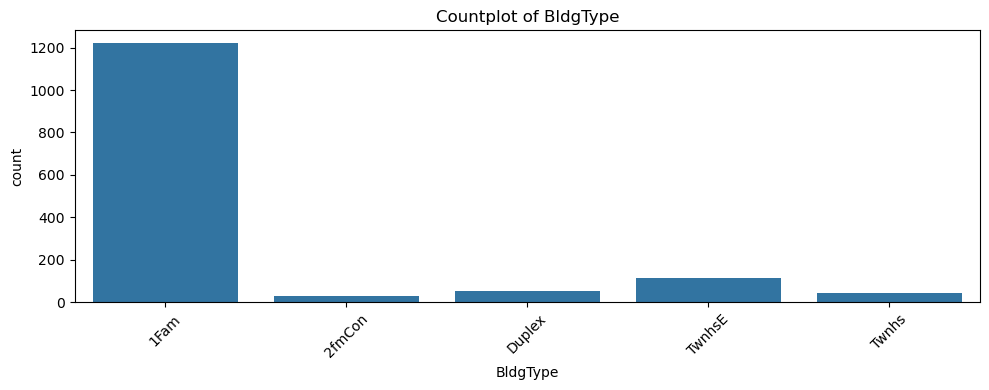

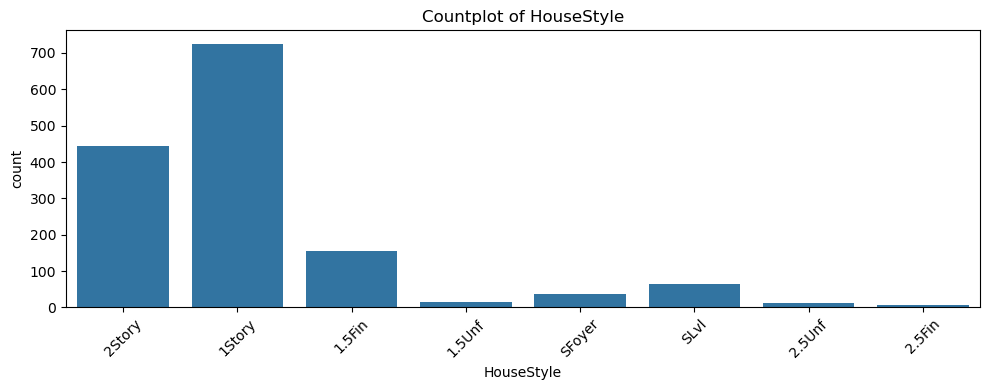

In [8]:
cols= ["Neighborhood","BldgType", "HouseStyle"]

for col in cols:
    plt.figure(figsize=(10,4))
    sns.countplot(data=df,x=col)
    plt.title(f"Countplot of {col}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## Bivariate Analysis

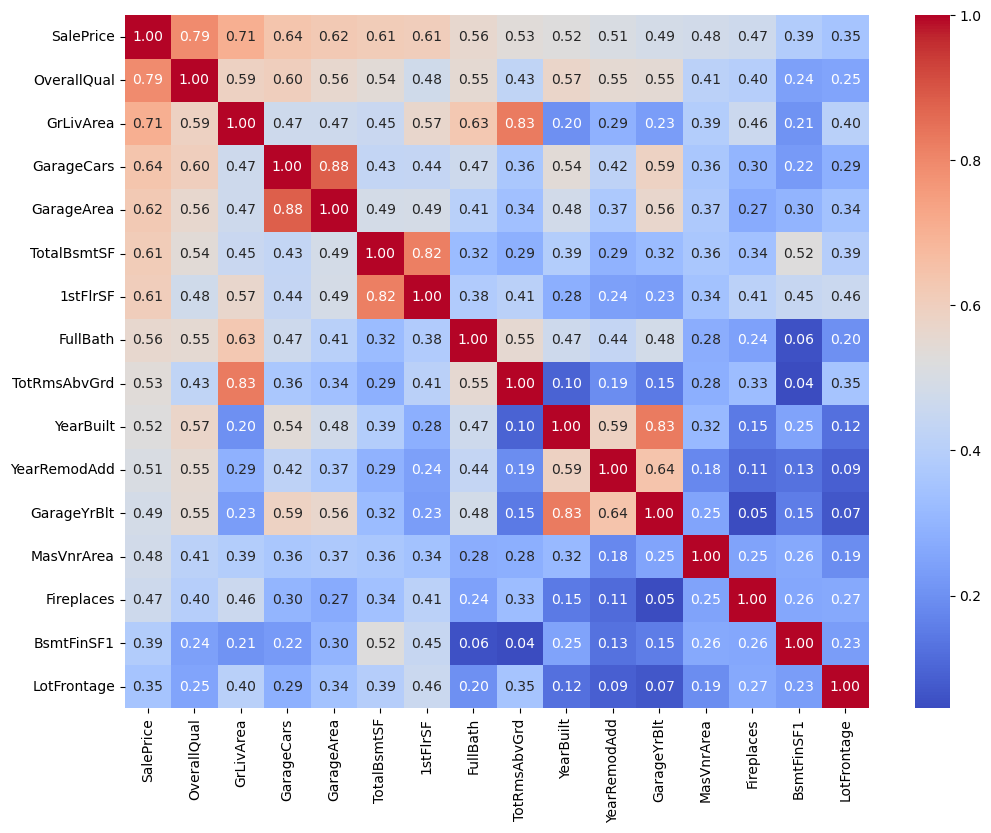

In [9]:
# Plot a heatmap of the top 15 features most correlated with SalePrice.

corr = df.corr(numeric_only=True)["SalePrice"].abs().sort_values(ascending=False)

top15 = corr.head(16).index
plt.figure(figsize=(12,9))
sns.heatmap(df[top15].corr(),annot=True,cmap="coolwarm",fmt=".2f")
plt.show()

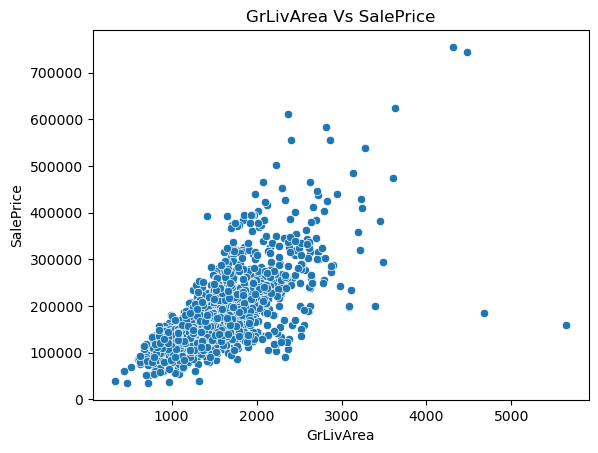

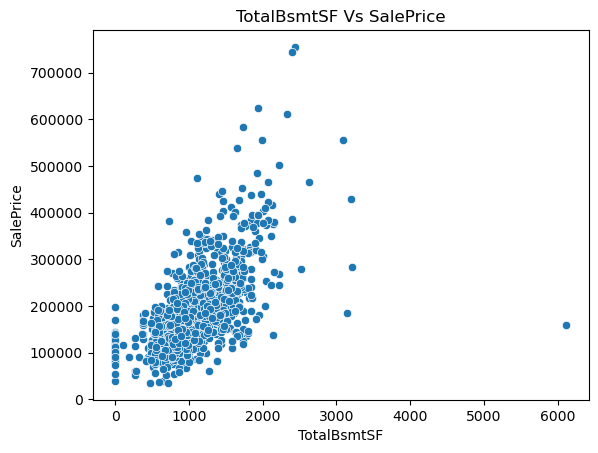

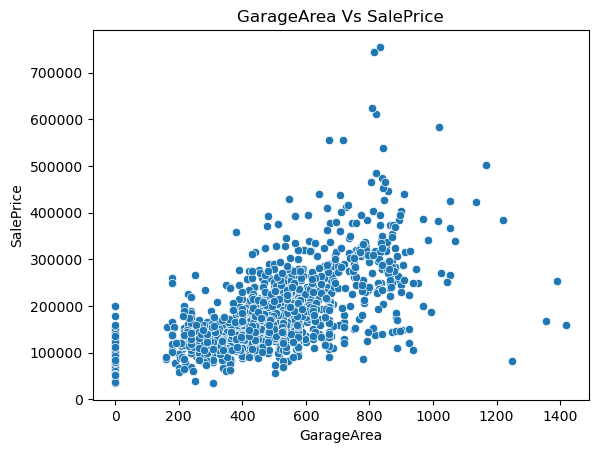

In [10]:
# Scatter plots: GrLivArea vs SalePrice, TotalBsmtSF vs SalePrice, GarageArea vs SalePrice.

cols = ["GrLivArea","TotalBsmtSF","GarageArea"]

for col in cols:
    sns.scatterplot(data=df,x=col,y="SalePrice")
    plt.title(f"{col} Vs SalePrice")
    plt.show()

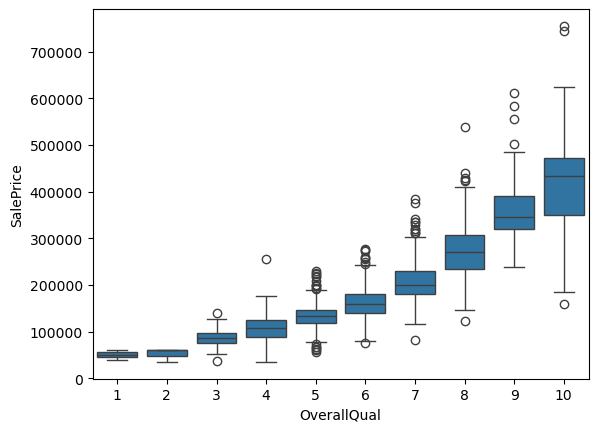

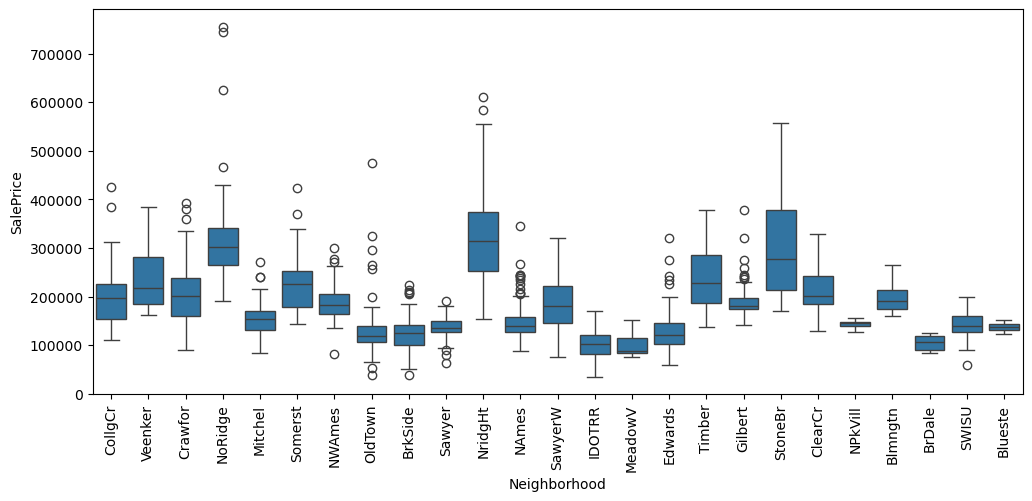

Neighborhood
NridgHt    315000.0
NoRidge    301500.0
StoneBr    278000.0
Timber     228475.0
Somerst    225500.0
Name: SalePrice, dtype: float64


In [11]:
# Boxplots: OverallQual vs SalePrice, Neighborhood vs SalePrice (which neighborhood is the priciest?).
# OverallQual vs SalePrice
sns.boxplot(data=df,x="OverallQual",y="SalePrice")
plt.show()

# Neighborhood vs SalePrice
plt.figure(figsize=(12,5))
sns.boxplot(data=df,x="Neighborhood",y="SalePrice")
plt.xticks(rotation = 90)
plt.show()

# Neighborhood with highest median SalePrice
print(df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False).head())

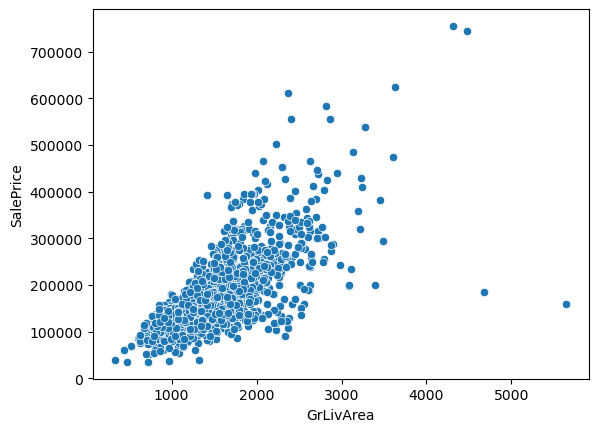

        Id  GrLivArea  SalePrice
523    524       4676     184750
1298  1299       5642     160000


In [12]:
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice")
plt.show()

# Find two extreme points
outliers = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]

print(outliers[["Id", "GrLivArea", "SalePrice"]])

# Flag outliers
df["Outlier"] = (
    (df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)
)

# Step 3: Data Preprocessing & Feature Engineering

## Handle Missing Values

In [13]:
# all columns with missing values and their missing %
isnull_df = df.isnull().sum()
isnull_pr = round(df.isnull().mean() *100,2)

isnull_df = pd.DataFrame({
    "Columns":isnull_df.index,
    "Missing Count":isnull_df.values,
    "Missing %":isnull_pr.values
})

display(isnull_df[isnull_df["Missing Count"]>0])

,Columns,Missing Count,Missing %
3,LotFrontage,259,17.74
6,Alley,1369,93.77
25,MasVnrType,872,59.73
26,MasVnrArea,8,0.55
30,BsmtQual,37,2.53
31,BsmtCond,37,2.53
32,BsmtExposure,38,2.60
33,BsmtFinType1,37,2.53
35,BsmtFinType2,38,2.60
42,Electrical,1,0.07


In [15]:
# Find columns with more than 80% missing values
drop_cols = isnull_df[isnull_df["Missing %"] > 80]["Columns"]

# Drop columns
df.drop(columns=drop_cols, inplace=True)

print("Dropped columns:", list(drop_cols))

Dropped columns: ['Alley', 'PoolQC', 'Fence', 'MiscFeature']


In [16]:
# For categorical columns where NaN means 'None' (e.g., PoolQC, Fence, GarageType) — fill with 'None'.
cat_none = [
    "PoolQC", "Fence", "GarageType", "GarageFinish",
    "GarageQual", "GarageCond", "Alley", "FireplaceQu",
    "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2", "MiscFeature"
]

for col in cat_none:
    if col in df.columns:
        df[col] = df[col].fillna("None")

In [17]:
# For numerical columns where NaN means 0 (e.g., GarageArea, BsmtFinSF1) — fill with 0.
num_zero = [
    "GarageArea", "GarageCars", "BsmtFinSF1",
    "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    "MasVnrArea", "WoodDeckSF", "OpenPorchSF",
    "EnclosedPorch", "3SsnPorch", "ScreenPorch",
    "PoolArea", "MiscVal"
]

for col in num_zero:
    if col in df.columns:
        df[col] = df[col].fillna(0)

In [20]:
# For remaining numerical columns — fill with median and Remaining categorical columns: fill with mode
for col in cat_col:
    if col in df.columns:
        if df[col].isnull().any():
            df[col] = df[col].fillna(df[col].mode()[0])

for col in num_col:
    if col in df.columns:
        if df[col].isnull().any():
            df[col] = df[col].fillna(df[col].median())


In [21]:
# Check remaining missing values
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


## Outlier Removal

In [23]:
# Remove the 2 outlier rows
df = df[~((df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000))]

print("New shape:", df.shape)

New shape: (1458, 78)


 #### 2. Why remove these outliers?
- These two houses have unusually large living areas but comparatively low sale prices.

- A linear regression model tries to fit a straight line through the data. These extreme points can pull the regression line toward themselves, changing the slope and reducing prediction accuracy for typical houses.

## Feature Engineering

In [26]:
# Total usable area
df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]

# House age
df["HouseAge"] = df["YrSold"] - df["YearBuilt"]

# Remodelling age
df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]

# Has garage: 1 if present, otherwise 0
df["HasGarage"] = (df["GarageArea"] > 0).astype(int)

# Has pool: 1 if present, otherwise 0
df["HasPool"] = (df["PoolArea"] > 0).astype(int)

# Check new features
print(df[["TotalSF", "HouseAge", "RemodAge", "HasGarage", "HasPool"]].head())

   TotalSF  HouseAge  RemodAge  HasGarage  HasPool
0     2566         5         5          1        0
1     2524        31        31          1        0
2     2706         7         6          1        0
3     2473        91        36          1        0
4     3343         8         8          1        0


C:\Users\MAYUR MAKVANA\AppData\Local\Temp\ipykernel_12852\536290441.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
C:\Users\MAYUR MAKVANA\AppData\Local\Temp\ipykernel_12852\536290441.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
C:\Users\MAYUR MAKVANA\AppData\Local\Temp\ipykernel_12852\536290441.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a D

## Encoding & Scaling

In [40]:
X = df.drop(columns=["SalePrice","Id"])
y = np.log1p(df["SalePrice"])

ordinal_cols = [
    c for c in ["ExterQual", "KitchenQual", "BsmtQual", "FireplaceQu"]
    if c in X.columns
]

num_cols = X.select_dtypes(include="number").columns.tolist()

skewed_cols = [
    c for c in num_cols if X[c].skew() > 0.75 and X[c].min() >= 0
]

normal_cols = [c for c in num_cols if c not in skewed_cols]

cat_cols = X.select_dtypes(include="object").columns.tolist()
nominal_cols = [c for c in cat_cols if X[c].nunique() <= 10
                and c not in ordinal_cols]

if "Neighborhood" in cat_cols:
    nominal_cols = [c for c in nominal_cols if c != "Neighborhood"]
    # Handle it separately with ordinal encoding
    neighborhood_cols = ["Neighborhood"]
else:
    neighborhood_cols = []

high_card_cols = [
    c for c in cat_cols
    if c not in ordinal_cols
    and c not in nominal_cols
    and c not in neighborhood_cols
]

X = X.drop(columns=high_card_cols)

quality_categories = ["None", "Po", "Fa", "TA", "Gd", "Ex"]

ordinal_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
    ("encoder", OrdinalEncoder(
        categories=[quality_categories] * len(ordinal_cols),
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

skew_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(
        np.log1p,
        feature_names_out="one-to-one"
    )),
    ("scaler", StandardScaler())
])

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

neighborhood_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value",
                               unknown_value=-1))
])

transformers = [
    ("quality", ordinal_pipe, ordinal_cols),
    ("skewed", skew_pipe, [c for c in skewed_cols if c in X.columns]),
    ("numeric", num_pipe, [c for c in normal_cols if c in X.columns]),
    ("categorical", cat_pipe, nominal_cols)
]

if neighborhood_cols:
    transformers.append(
        ("neighborhood", neighborhood_pipe, neighborhood_cols)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

## Train-Test Split

In [35]:
# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Print shapes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1166, 79)
X_test: (292, 79)
y_train: (1166,)
y_test: (292,)


# Step 4: Regression Models — Linear, Ridge & Lasso

## Linear Regression (Baseline)

RMSE: 22769.76
MAE: 15857.11
R2 Score: 0.9061


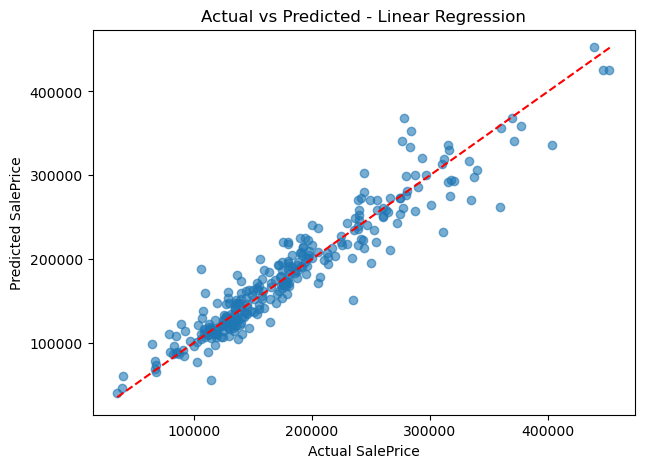

In [37]:
model = Pipeline([
    ("perprocessor",preprocessor),
    ("regressor",LinearRegression())
])

# Train model
model.fit(X_train, y_train)

# Predict (predictions are in log scale)
y_pred_log = model.predict(X_test)

# Convert back to original price scale
y_pred = np.expm1(y_pred_log)
y_actual = np.expm1(y_test)

# Evaluation metrics
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
mae = mean_absolute_error(y_actual, y_pred)
r2 = r2_score(y_actual, y_pred)

print("RMSE:", round(rmse, 2))
print("MAE:", round(mae, 2))
print("R2 Score:", round(r2, 4))

# Actual vs Predicted plot
plt.figure(figsize=(7, 5))
plt.scatter(y_actual, y_pred, alpha=0.6)

# Perfect prediction diagonal
minimum = min(y_actual.min(), y_pred.min())
maximum = max(y_actual.max(), y_pred.max())

plt.plot([minimum, maximum], [minimum, maximum], "r--")

plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("Actual vs Predicted - Linear Regression")
plt.show()

## Ridge Regression (L2)

Best Alpha: 10.0
RMSE: 20541.88
MAE: 14696.27
R2 Score: 0.9236


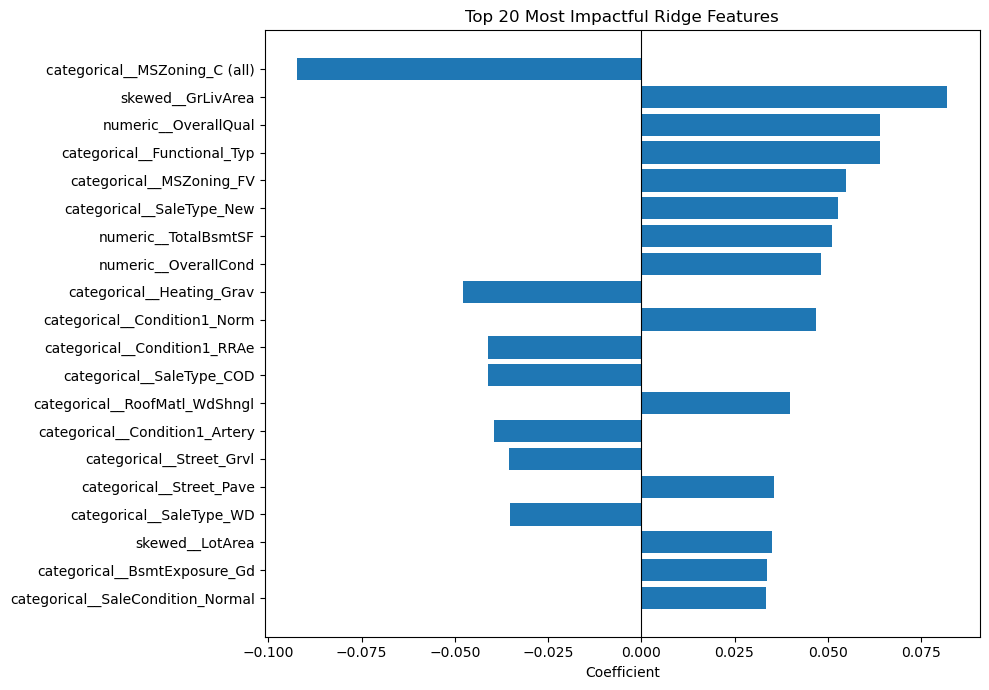

In [42]:
ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RidgeCV(alphas=[0.01, 0.1, 1, 10, 100]))
])


ridge_model.fit(X_train, y_train)


ridge = ridge_model.named_steps["regressor"]
print("Best Alpha:", ridge.alpha_)


y_pred = np.expm1(ridge_model.predict(X_test))
y_actual = np.expm1(y_test)


print("RMSE:", round(np.sqrt(mean_squared_error(y_actual, y_pred)), 2))
print("MAE:", round(mean_absolute_error(y_actual, y_pred), 2))
print("R2 Score:", round(r2_score(y_actual, y_pred), 4))


feature_names = ridge_model.named_steps["preprocessor"].get_feature_names_out()
coefficients = ridge.coef_

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})


top20 = coef_df.reindex(
    coef_df["Coefficient"].abs().sort_values(ascending=False).head(20).index
)


plt.figure(figsize=(10, 7))
plt.barh(top20["Feature"], top20["Coefficient"])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient")
plt.title("Top 20 Most Impactful Ridge Features")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Lasso Regression (L1)

In [44]:
lasso_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LassoCV(
        alphas=[0.0001, 0.001, 0.01, 0.1, 1],
        max_iter=10000
    ))
])


lasso_model.fit(X_train, y_train)


lasso = lasso_model.named_steps["regressor"]
print("Best Alpha:", lasso.alpha_)


zero_features = np.sum(lasso.coef_ == 0)
print("Features zeroed out:", zero_features)
print("Total features:", len(lasso.coef_))


y_pred = np.expm1(lasso_model.predict(X_test))
y_actual = np.expm1(y_test)


print("RMSE:", round(np.sqrt(mean_squared_error(y_actual, y_pred)), 2))
print("MAE:", round(mean_absolute_error(y_actual, y_pred), 2))
print("R2 Score:", round(r2_score(y_actual, y_pred), 4))

Best Alpha: 0.001
Features zeroed out: 147
Total features: 215
RMSE: 20032.6
MAE: 14610.47
R2 Score: 0.9273


# Step 5: Advanced Models — Random Forest & XGBoost Regressor

## Random Forest Regressor

RMSE: 23226.4
MAE: 16344.3
R2 Score: 0.9023


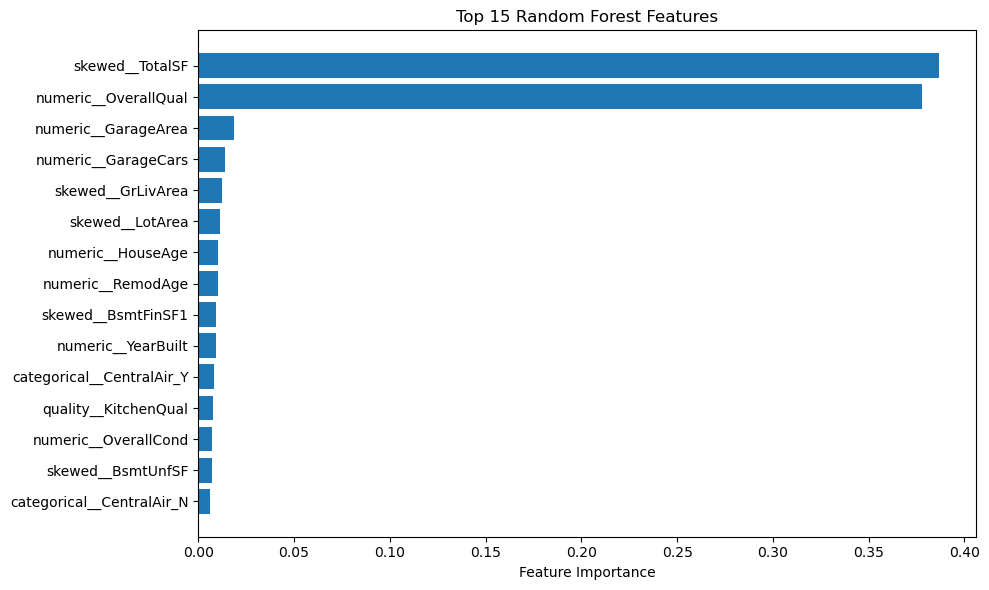

In [46]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])


rf_model.fit(X_train, y_train)


y_pred = np.expm1(rf_model.predict(X_test))
y_actual = np.expm1(y_test)


print("RMSE:", round(np.sqrt(mean_squared_error(y_actual, y_pred)), 2))
print("MAE:", round(mean_absolute_error(y_actual, y_pred), 2))
print("R2 Score:", round(r2_score(y_actual, y_pred), 4))


feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()
importance = rf_model.named_steps["regressor"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})


top15 = importance_df.sort_values(
    "Importance", ascending=False
).head(15)


plt.figure(figsize=(10, 6))
plt.barh(top15["Feature"], top15["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.title("Top 15 Random Forest Features")
plt.tight_layout()
plt.show()

## XGBoost Regressor

RMSE: 19396.12
MAE: 14039.56
R2 Score: 0.9319


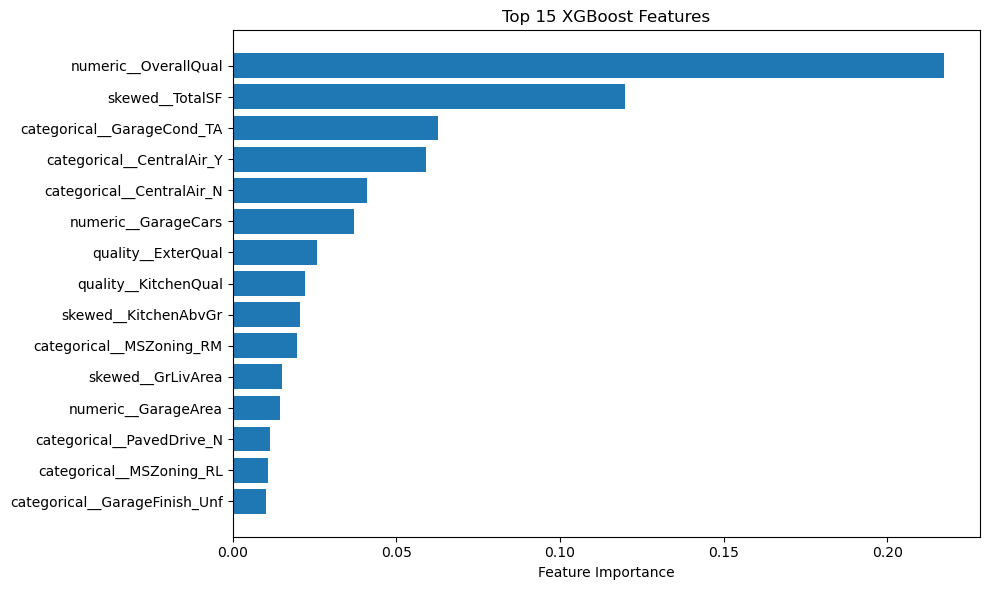

In [48]:
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    ))
])


xgb_model.fit(X_train, y_train)


y_pred = np.expm1(xgb_model.predict(X_test))
y_actual = np.expm1(y_test)


print("RMSE:", round(np.sqrt(mean_squared_error(y_actual, y_pred)), 2))
print("MAE:", round(mean_absolute_error(y_actual, y_pred), 2))
print("R2 Score:", round(r2_score(y_actual, y_pred), 4))

feature_names = xgb_model.named_steps["preprocessor"].get_feature_names_out()
importance = xgb_model.named_steps["regressor"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})


top15 = importance_df.sort_values(
    "Importance", ascending=False
).head(15)


plt.figure(figsize=(10, 6))
plt.barh(top15["Feature"], top15["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.title("Top 15 XGBoost Features")
plt.tight_layout()
plt.show()

## Cross-Validation

In [51]:
cv_scores = cross_val_score(
    xgb_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)


cv_rmse = -cv_scores

print("Mean CV RMSE:", round(cv_rmse.mean(), 4))
print("Std Deviation:", round(cv_rmse.std(), 4))
print(f"CV RMSE: {cv_rmse.mean():.4f} ± {cv_rmse.std():.4f}")

Mean CV RMSE: 0.1226
Std Deviation: 0.0091
CV RMSE: 0.1226 ± 0.0091


In [52]:
test_rmse_log = np.sqrt(
    mean_squared_error(y_test, xgb_model.predict(X_test))
)

print("Test RMSE (log scale):", round(test_rmse_log, 4))
print("Mean CV RMSE:", round(cv_rmse.mean(), 4))

Test RMSE (log scale): 0.1176
Mean CV RMSE: 0.1226


- The mean CV RMSE is 0.1226 ± 0.0091, while the test RMSE is 0.1176. Both values are close, indicating that the XGBoost model performs consistently on the validation folds and the test set. The slightly lower test RMSE suggests that the test set may be a little easier to predict than the average cross-validation fold.

## Hyperparameter Tuning — XGBoost

In [54]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor(random_state=42))
])


param_grid = {
    "regressor__n_estimators": [200, 300, 500, 700],
    "regressor__max_depth": [3, 4, 5, 6, 7],
    "regressor__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "regressor__subsample": [0.7, 0.8, 0.9, 1.0],
    "regressor__colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}


random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid,
    n_iter=20,
    cv=3,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)


random_search.fit(X_train, y_train)


print("Best Parameters:", random_search.best_params_)
print("Best CV RMSE:", round(-random_search.best_score_, 4))


best_model = random_search.best_estimator_


y_pred = np.expm1(best_model.predict(X_test))
y_actual = np.expm1(y_test)


print("Test RMSE:", round(np.sqrt(mean_squared_error(y_actual, y_pred)), 2))
print("Test MAE:", round(mean_absolute_error(y_actual, y_pred), 2))
print("Test R2:", round(r2_score(y_actual, y_pred), 4))

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters: {'regressor__subsample': 0.8, 'regressor__n_estimators': 300, 'regressor__max_depth': 3, 'regressor__learning_rate': 0.03, 'regressor__colsample_bytree': 0.8}
Best CV RMSE: 0.1224
Test RMSE: 19994.4
Test MAE: 14494.96
Test R2: 0.9276


# Step 6: Model Evaluation & Comparison

In [59]:
models = {
    "Linear Regression": model,
    "Ridge": ridge_model,
    "Lasso": lasso_model,
    "Random Forest": rf_model,
    "XGBoost": best_model
}

results = []
predictions = {}

for name, estimator in models.items():
    start = time.time()
    estimator.fit(X_train, y_train)
    train_time = time.time() - start

    pred = np.expm1(estimator.predict(X_test))
    actual = np.expm1(y_test)

    predictions[name] = pred

    rmse = np.sqrt(mean_squared_error(actual, pred))
    mae = mean_absolute_error(actual, pred)
    r2 = r2_score(actual, pred)

    results.append({
        "Model": name,
        "RMSE ($)": rmse,
        "MAE ($)": mae,
        "R2 Score": r2,
        "Training Time (s)": train_time
    })

comparison = pd.DataFrame(results)
comparison

,Model,RMSE ($),MAE ($),R2 Score,Training Time (s)
0,Linear Regression,22769.763247,15857.109661,0.906139,0.049168
1,Ridge,20541.880344,14696.274731,0.923608,0.087366
2,Lasso,20032.597079,14610.470585,0.927349,0.440836
3,Random Forest,23226.396816,16344.301827,0.902337,0.497648
4,XGBoost,19994.396382,14494.963078,0.927626,0.267348


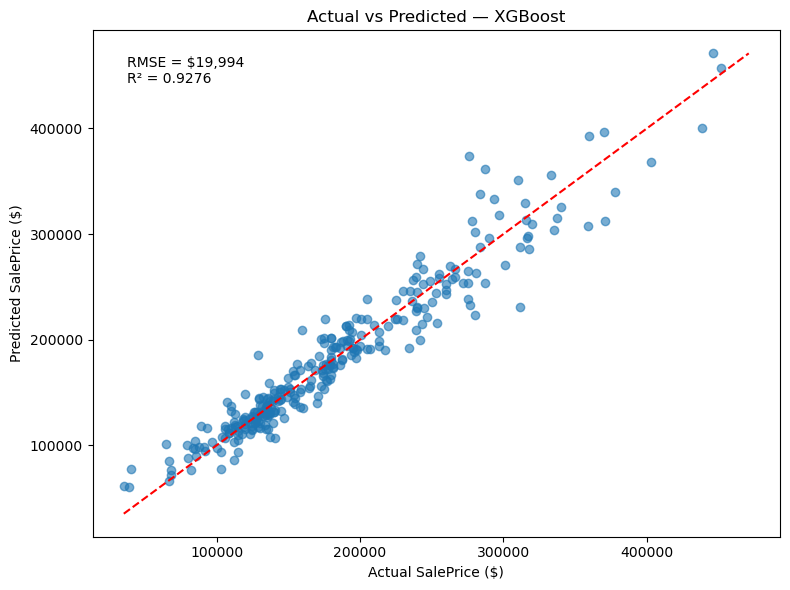

Best model: XGBoost


In [68]:
# Select best model by test RMSE
best_name = comparison.loc[
    comparison["RMSE ($)"].idxmin(), "Model"
]

best_pred = predictions[best_name]
actual = np.expm1(y_test)

rmse = np.sqrt(mean_squared_error(actual, best_pred))
r2 = r2_score(actual, best_pred)

plt.figure(figsize=(8, 6))
plt.scatter(actual, best_pred, alpha=0.6)

# Perfect prediction line
low = min(actual.min(), best_pred.min())
high = max(actual.max(), best_pred.max())

plt.plot([low, high], [low, high], "r--")

plt.xlabel("Actual SalePrice ($)")
plt.ylabel("Predicted SalePrice ($)")
plt.title(f"Actual vs Predicted — {best_name}")

plt.text(
    0.05, 0.95,
    f"RMSE = ${rmse:,.0f}\nR² = {r2:.4f}",
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.tight_layout()
plt.show()

print("Best model:", best_name)

# Step 7: Residual Analysis & Model Interpretation

## Residual Plots

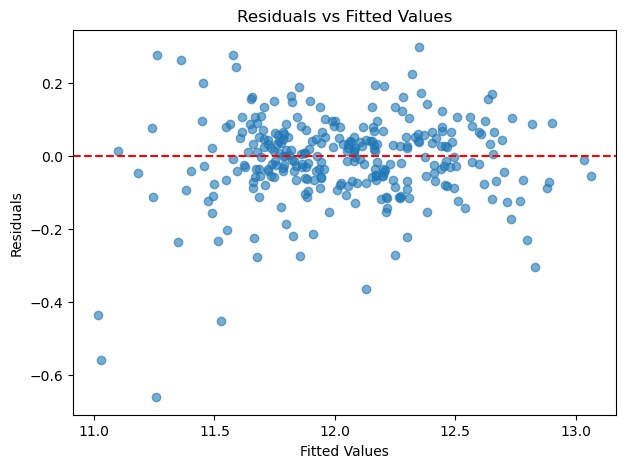

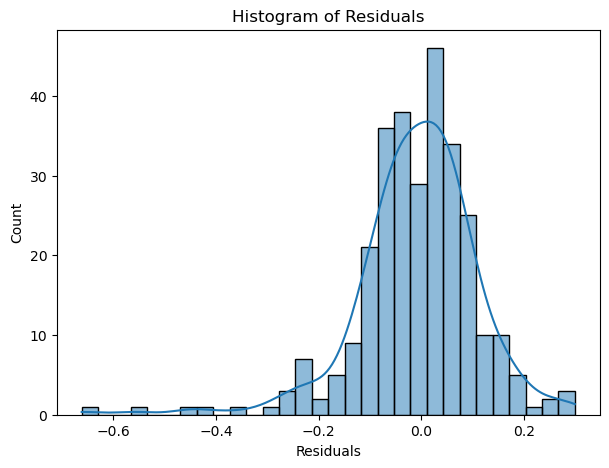

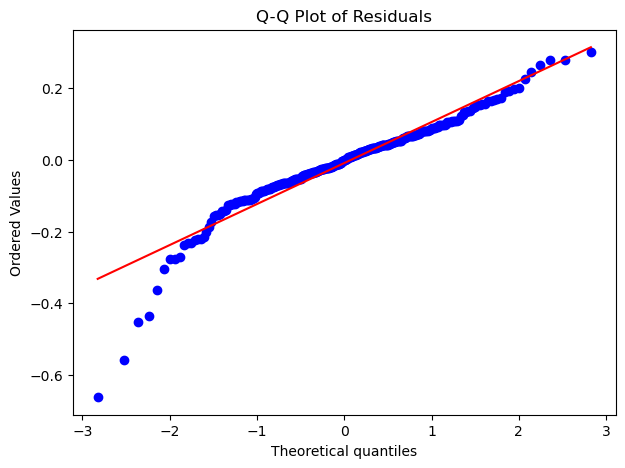

In [69]:
y_pred = best_model.predict(X_test)

residuals = y_test - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")
plt.show()


plt.figure(figsize=(7, 5))
sns.histplot(residuals, bins=30, kde=True)
plt.xlabel("Residuals")
plt.title("Histogram of Residuals")
plt.show()

plt.figure(figsize=(7, 5))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot of Residuals")
plt.show()

## Business Interpretation

,Feature,Importance
0,numeric__OverallQual,0.171574
1,skewed__TotalSF,0.104013
2,quality__ExterQual,0.092984
3,quality__KitchenQual,0.045744
4,numeric__GarageCars,0.040552


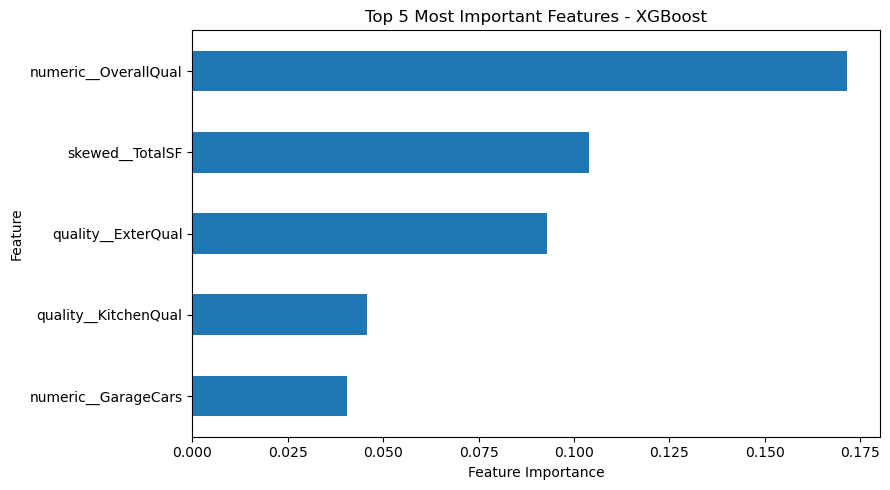

In [71]:
preprocessor = best_model.named_steps["preprocessor"]
xgb_model = best_model.named_steps["regressor"]


feature_names = preprocessor.get_feature_names_out()


importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

top5_features = (
    importance_df
    .sort_values("Importance", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

display(top5_features)

top5_features.sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(9, 5)
)

plt.title("Top 5 Most Important Features - XGBoost")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()

Top 5 Most Important Features — XGBoost
1. OverallQual: Sabse important feature hai. Ye house ki overall quality batata hai.
2. TotalSF: House ka total area jitna zyada hoga, price par utna effect pad sakta hai.
3. ExterQual: House ke exterior ki quality price predict karne mein important hai.
4. KitchenQual: Kitchen ki quality bhi house price ko predict karne mein help karti hai.
5. GarageCars: Garage mein kitni cars aa sakti hain, ye bhi price prediction mein useful hai.

# step 8: Pipeline, Deployment

### Deployment

In [74]:
pipeline = best_model

joblib.dump(pipeline,model_path/"house_price_model.pkl")

print("Pipeline saved successfully!")

Pipeline saved successfully!


### Load and Test

In [76]:
loaded_model = joblib.load(model_path/"house_price_model.pkl")

X_sample = X_test.head(5)
y_actual = np.expm1(y_test.head(5))

y_pred = np.expm1(loaded_model.predict(X_sample))

result = pd.DataFrame({
    "Actual Price": y_actual.values,
    "Predicted Price": y_pred
})

print(result.round(2))

   Actual Price  Predicted Price
0      190000.0     212522.43750
1      100000.0      97847.59375
2      115000.0     113691.59375
3      159000.0     153360.43750
4      315500.0     313510.68750
